# Итоги осени сети «Зерно»

Самостоятельный отчёт SQL-аналитика. Заказы сентября–ноября 2026 года. Получатель — руководитель сети: где выросли продажи, как сопоставимы точки, какие выводы допустимы о карте и новом напитке. Для повтора положите блокнот в папку рядом с data/ и выполните сверху вниз в Python с pandas, matplotlib и IPython. Окружение и версии напечатаны ниже.

**Файлы:** data/orders_3m.csv, data/shops.csv, data/menu.csv рядом с блокнотом; также поддерживается ../data. **Проверенное окружение:** Python 3.12.14, pandas 3.0.6, DuckDB 1.5.6, matplotlib 3.10.9, IPython 9.18.1. Для осеннего отчёта DuckDB не требуется. Установка: `python -m pip install pandas matplotlib ipython`; для запуска в Jupyter установите `jupyterlab ipykernel`.

In [1]:
import sys
from pathlib import Path

import pandas as pd

def data_folder(*files):
    for folder in (Path("data"), Path("../data")):
        if all((folder / filename).is_file() for filename in files):
            print("Папка данных:", folder.resolve())
            return folder
    raise FileNotFoundError("В data/ и ../data/ нет полного набора: " + ", ".join(files))

print("Python", sys.version.split()[0], "| pandas", pd.__version__)

Python 3.12.14 | pandas 3.0.6


In [2]:
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
print("matplotlib", __import__("matplotlib").__version__)

matplotlib 3.10.9


## 1. Цель и правила решения

До расчётов фиксирую правила брифа. H1: оба прироста помесячной выручки >0. H2: есть общая кофейня среди всех лидеров по местам и всех лидеров по выручке. H3: сезонный напиток вызвал рост ноября — причинный вывод по этим данным недоступен, нужен эксперимент. H4: чек заказов с картой как минимум на 5% выше чека без карты. H5: максимальная клетка нагрузки — выходной до 12:00. H6: маржа «не кофе» выше кофе минимум на 3 процентных пункта.

Результат — шесть вердиктов, показатели по городам и точкам и действия для руководителя. Вывод о выполнении описательного порога не означает статистическую значимость или причинный эффект.

## 2. Данные и проверки качества

Три входа: orders_3m.csv — одна строка на заказ одного напитка, qty чашек; shops.csv — кофейни и места; menu.csv — категории и себестоимость чашки S. Сверяю типы, период, дубли, ключи и пропуски до соединения.

In [3]:
DATA = data_folder('orders_3m.csv', 'shops.csv', 'menu.csv')
import pandas as pd
df=pd.read_csv(DATA / "orders_3m.csv",parse_dates=["datetime"])
shops=pd.read_csv(DATA / "shops.csv")
menu=pd.read_csv(DATA / "menu.csv")
full=df.merge(shops,on="shop_id",how="left",validate="many_to_one").merge(menu,on="drink",how="left",validate="many_to_one")
same_rows=len(full)==len(df)
print(df.shape, shops.shape, menu.shape)
print(df.dtypes)
print(df["datetime"].min(),df["datetime"].max())
print(df.isna().sum())
print("Полные дубли",df.duplicated().sum(),"Дубли order_id",df["order_id"].duplicated().sum())
assert shops["shop_id"].notna().all() and shops["shop_id"].is_unique
assert menu["drink"].notna().all() and menu["drink"].is_unique
assert full[["city","seats","category","cost_s"]].notna().all().all()
assert same_rows
assert (df["amount"]>0).all() and (df["qty"]>0).all()
display(df.head(1),shops.head(1),menu.head(1))

Папка данных: /private/tmp/kuch02round/student-retest/data
(2089, 9) (7, 5) (11, 4)
order_id                str
datetime     datetime64[us]
shop_id                 str
drink                   str
size                    str
qty                   int64
amount                int64
client_id               str
channel                 str
dtype: object
2026-09-01 08:06:00 2026-11-30 21:39:00
order_id       0
datetime       0
shop_id        0
drink          0
size           0
qty            0
amount         0
client_id    842
channel        0
dtype: int64
Полные дубли 0 Дубли order_id 0


,order_id,datetime,shop_id,drink,size,qty,amount,client_id,channel
0,O-00001,2026-09-01 10:31:00,PRM-1,Капучино,S,2,380,C1237,зал


,shop_id,city,name,opened,seats
0,PRM-1,Пермь,Ленина,2021-03-01,24


,drink,category,price_s,cost_s
0,Эспрессо,кофе,120,28


In [4]:
from IPython.display import display, Markdown
quality=f"**Вывод по данным.** {len(df)} заказов, {df['shop_id'].nunique()} продающих кофеен, {df['drink'].nunique()} напитков; справочник включает {len(shops)} кофеен. Пропусков client_id — {df['client_id'].isna().sum()}, это заказы без карты, не неизвестная сумма. Дубли строк и order_id: {df.duplicated().sum()} и {df['order_id'].duplicated().sum()}. После двух LEFT JOIN осталось {len(full)} строк, ключевые атрибуты найдены."
display(Markdown(quality))

**Вывод по данным.** 2089 заказов, 6 продающих кофеен, 11 напитков; справочник включает 7 кофеен. Пропусков client_id — 842, это заказы без карты, не неизвестная сумма. Дубли строк и order_id: 0 и 0. После двух LEFT JOIN осталось 2089 строк, ключевые атрибуты найдены.

**Качество и ограничения.** Исходные строки сохраняю: нули в идентификатор карты не подставляю, повторные визиты не удаляю. У EKB-1 нет заказов в выгрузке: отсутствие продаж не доказывает отсутствие работы. Для сравнения продаж ниже использую продающие точки и отдельно показываю покрытие справочника. Места — грубый знаменатель: доставка и заказы с собой могут не занимать место. Себестоимость — расчёт по коэффициентам размера без аренды, труда и других расходов, поэтому маржа здесь не чистая прибыль. Проверки кардинальности и полноты атрибутов пройдены; причинность и люди без карты из этих файлов не восстанавливаются.

## 3. Предобработка

Дата прочитана как datetime при загрузке, справочники присоединены many_to_one. Пропуски карты сохранены для разделения заказов; суммы не округляю до агрегирования.

In [5]:
print("Заказов без соответствия кофейне:", (~df["shop_id"].isin(shops["shop_id"])).sum())
print("Заказов без соответствия меню:", (~df["drink"].isin(menu["drink"])).sum())
print("Кофейни без заказов:", shops.loc[~shops["shop_id"].isin(df["shop_id"]),"shop_id"].tolist())

Заказов без соответствия кофейне: 0
Заказов без соответствия меню: 0
Кофейни без заказов: ['EKB-1']


**Вывод.** Несопоставленных заказов 0. У EKB-1 заказов нет; эта точка остаётся в справочнике, но не создаёт фиктивные строки заказов. Удаление или заполнение исходных наблюдений не потребовалось.

## 4.1. H1: сеть растёт каждый месяц

In [6]:
monthly=full.groupby(full["datetime"].dt.to_period("M")).agg(revenue=("amount","sum"),orders=("order_id","size"),avg_check=("amount","mean"),clients=("client_id","nunique"))
monthly["avg_check"]=monthly["avg_check"].round(1)
nov_vs_oct=round((monthly["revenue"].iloc[-1]/monthly["revenue"].iloc[-2]-1)*100,1)

growth=monthly["revenue"].pct_change()*100
display(monthly)
orders_growth=(monthly["orders"].iloc[-1]/monthly["orders"].iloc[-2]-1)*100
checks=full.groupby(full["datetime"].dt.to_period("M"))["amount"].mean()
check_growth=(checks.iloc[-1]/checks.iloc[-2]-1)*100
display(Markdown(f"**Вывод H1.** Выручка: {monthly['revenue'].tolist()} ₽; приросты {growth.dropna().round(1).tolist()}%. H1 подтвердилась, оба больше нуля. В ноябре заказов {orders_growth:+.1f}%, чек {check_growth:+.1f}%; их произведение даёт рост выручки {nov_vs_oct:+.1f}%, это два рычага роста."))

,revenue,orders,avg_check,clients
datetime,,,,
2026-09,220241,651,338.3,201
2026-10,233756,700,333.9,208
2026-11,256198,738,347.2,214


**Вывод H1.** Выручка: [220241, 233756, 256198] ₽; приросты [6.1, 9.6]%. H1 подтвердилась, оба больше нуля. В ноябре заказов +5.4%, чек +4.0%; их произведение даёт рост выручки +9.6%, это два рычага роста.

## 4.2. H2: вместительность и лидеры продаж

In [7]:
by_shop=full.groupby("shop_id").agg(city=("city","first"),revenue=("amount","sum"),seats=("seats","first"))
by_shop["per_seat"]=(by_shop["revenue"]/by_shop["seats"]).round()
by_shop=by_shop.sort_values("per_seat",ascending=False)
leader=by_shop["per_seat"].idxmax()
leader_by_revenue=by_shop["revenue"].idxmax()

by_city=full.groupby("city").agg(revenue=("amount","sum"),orders=("order_id","size"),shops=("shop_id","nunique"))
by_city["revenue_per_shop"]=by_city["revenue"]/by_city["shops"]
display(by_shop,by_city)
most_seats=set(by_shop.index[by_shop["seats"]==by_shop["seats"].max()])
most_revenue=set(by_shop.index[by_shop["revenue"]==by_shop["revenue"].max()])
display(Markdown(f"**Вывод H2.** Лидеры по местам {sorted(most_seats)}, по выручке {sorted(most_revenue)}. Общие лидеры: {sorted(most_seats & most_revenue)} — H2 {'подтвердилась' if most_seats & most_revenue else 'не подтвердилась'}. По общей выручке на место лидирует {leader}: {by_shop.loc[leader,'per_seat']:.0f} ₽. Общая выручка города зависит от числа точек, поэтому рядом указана выручка на продающую кофейню."))

,city,revenue,seats,per_seat
shop_id,,,,
PRM-1,Пермь,186163,24,7757.0
KZN-1,Казань,181365,30,6046.0
KZN-2,Казань,98340,18,5463.0
TMN-1,Тюмень,96489,20,4824.0
PRM-2,Пермь,75377,16,4711.0
UFA-1,Уфа,72461,22,3294.0


,revenue,orders,shops,revenue_per_shop
city,,,,
Казань,279705,833,2,139852.5
Пермь,261540,741,2,130770.0
Тюмень,96489,294,1,96489.0
Уфа,72461,221,1,72461.0


**Вывод H2.** Лидеры по местам ['KZN-1'], по выручке ['PRM-1']. Общие лидеры: [] — H2 не подтвердилась. По общей выручке на место лидирует PRM-1: 7757 ₽. Общая выручка города зависит от числа точек, поэтому рядом указана выручка на продающую кофейню.

**Граница показателя.** Общая выручка на место включает доставку и заказы навынос. Она не измеряет использование мест или загрузку зала. Для загрузки нужны занятые место-часы и доступные место-часы, часы работы и длительность визитов. Дополнительная доставка увеличит per_seat даже при пустом зале.

## 4.3. H3: сезонный напиток и рост ноября

In [8]:
nov=full[full["datetime"].dt.month==11]
october=full[full["datetime"].dt.month==10]
new_drinks=set(nov["drink"])-set(full.loc[full["datetime"].dt.month<11,"drink"])
seasonal_share=round(nov.loc[nov["drink"].isin(new_drinks),"amount"].sum()/nov["amount"].sum()*100,1)
check_change=round((nov["amount"].mean()/october["amount"].mean()-1)*100,1)

display(nov.groupby("drink")["amount"].sum())
display(Markdown(f"**Вывод H3.** Новые напитки: {sorted(new_drinks)}, доля выручки ноября {seasonal_share:.1f}%; чек изменился на {check_change:+.1f}%. Гипотеза не опровергнута, нужен эксперимент: совместный рост не доказывает вклад напитка. Предлагаю случайное предложение напитка сопоставимым гостям с контролем; целевая метрика — выручка на участника, проверять каннибализацию других напитков."))

drink
Американо    21929
Какао        14040
Капучино     36512
Латте        40642
Матча        10741
Мокко        14760
Раф          32305
Сезонный     39970
Флэт уайт    31199
Чай           8820
Эспрессо      5280
Name: amount, dtype: int64

**Вывод H3.** Новые напитки: ['Сезонный'], доля выручки ноября 15.6%; чек изменился на +4.0%. Гипотеза не опровергнута, нужен эксперимент: совместный рост не доказывает вклад напитка. Предлагаю случайное предложение напитка сопоставимым гостям с контролем; целевая метрика — выручка на участника, проверять каннибализацию других напитков.

## 4.4. H4: заказы с картой и без

In [9]:
card=full.loc[full["client_id"].notna(),"amount"].mean()
no_card=full.loc[full["client_id"].isna(),"amount"].mean()
avg_card=round(card,1)
avg_no_card=round(no_card,1)
diff_pct=round((card/no_card-1)*100,1)

card_n=full["client_id"].notna().sum()
display(Markdown(f"**Вывод H4.** С картой {card_n} заказов, средний чек {avg_card:.1f} ₽; без карты {len(full)-card_n}, чек {avg_no_card:.1f} ₽. Разница {diff_pct:+.1f}% при пороге 5% — H4 {'подтвердилась' if (card/no_card-1)*100>=5 else 'не подтвердилась'}. Это сравнение заказов, а не причинный эффект оформления карты и не средняя выручка на человека."))

**Вывод H4.** С картой 1247 заказов, средний чек 343.2 ₽; без карты 842, чек 335.2 ₽. Разница +2.4% при пороге 5% — H4 не подтвердилась. Это сравнение заказов, а не причинный эффект оформления карты и не средняя выручка на человека.

## 4.5. H5: пик нагрузки

datetime,8,9,10,11,12,13,14,15,16,17,18,19,20,21
datetime,,,,,,,,,,,,,,
0,15,26,27,17,28,22,25,10,15,23,17,14,15,8
1,12,39,29,22,28,28,13,9,16,18,29,19,10,5
2,14,41,24,15,25,23,23,7,17,20,17,25,13,11
3,16,19,26,20,18,36,22,16,14,14,23,17,15,4
4,28,39,24,29,23,21,10,9,17,19,18,17,15,8
5,27,56,42,24,29,36,26,25,23,22,23,25,16,6
6,25,35,36,28,29,36,26,21,17,24,28,23,17,13


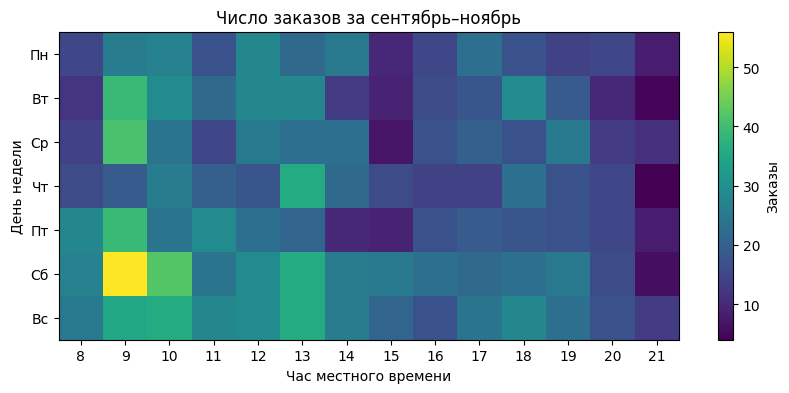

**Вывод H5.** Максимум 56 заказов: день недели 5 (0=понедельник), час 9. H5 подтвердилась. Планирование смен стоит уточнить по отдельным кофейням: агрегат сети скрывает местные пики и считает заказы, не чашки.

In [10]:
load=pd.pivot_table(full,index=full["datetime"].dt.weekday,columns=full["datetime"].dt.hour,values="order_id",aggfunc="count",fill_value=0)
peak=load.stack().idxmax()

display(load)
fig,ax=plt.subplots(figsize=(10,4))
im=ax.imshow(load,aspect="auto")
ax.set_xticks(range(len(load.columns)),load.columns)
ax.set_yticks(range(7),["Пн","Вт","Ср","Чт","Пт","Сб","Вс"])
ax.set_xlabel("Час местного времени")
ax.set_ylabel("День недели")
ax.set_title("Число заказов за сентябрь–ноябрь")
fig.colorbar(im,ax=ax,label="Заказы")
plt.show()
display(Markdown(f"**Вывод H5.** Максимум {load.loc[peak[0],peak[1]]} заказов: день недели {peak[0]} (0=понедельник), час {peak[1]}. H5 {'подтвердилась' if peak[0] in [5,6] and peak[1]<12 else 'не подтвердилась'}. Планирование смен стоит уточнить по отдельным кофейням: агрегат сети скрывает местные пики и считает заказы, не чашки."))

## 4.6. H6: маржа категорий

In [11]:
SIZE_K={"S":1.,"M":1.25,"L":1.5}
full["cost"]=full["cost_s"]*full["size"].map(SIZE_K)*full["qty"]
g=full.groupby("category").agg(revenue=("amount","sum"),cost=("cost","sum"))
margin_raw=(g["revenue"]-g["cost"])/g["revenue"]*100
margin=margin_raw.round(1)

display(g.assign(margin_pct=margin))
delta=margin_raw["не кофе"]-margin_raw["кофе"]
display(Markdown(f"**Вывод H6.** Маржа кофе {margin_raw['кофе']:.1f}%, не кофе {margin_raw['не кофе']:.1f}%; разница {delta:+.1f} п.п. при пороге +3 — H6 {'подтвердилась' if delta>=3 else 'не подтвердилась'}. Расчёт взвешен рублями, а не средним процентов заказов. Для решения о меню дополнительно нужны трудозатраты и спрос."))

,revenue,cost,margin_pct
category,,,
кофе,604196,145381.25,75.9
не кофе,105999,24075.00,77.3


**Вывод H6.** Маржа кофе 75.9%, не кофе 77.3%; разница +1.3 п.п. при пороге +3 — H6 не подтвердилась. Расчёт взвешен рублями, а не средним процентов заказов. Для решения о меню дополнительно нужны трудозатраты и спрос.

**Маржинальность и решение об акции.** Доля маржи на рубль выручки отвечает одному вопросу, маржа дополнительной чашки — другому. Для выбора акции нужны ожидаемый дополнительный объём, маржа в рублях и расходы на продвижение. Прохождение порога H6 не выбирает акцию автоматически.

## 5. Вердикты и рекомендации

In [12]:
def verdict(ok):
    return "подтвердилась" if ok else "не подтвердилась"
most_seats=set(by_shop.index[by_shop["seats"]==by_shop["seats"].max()])
most_revenue=set(by_shop.index[by_shop["revenue"]==by_shop["revenue"].max()])
verdicts={"H1":verdict((monthly["revenue"].pct_change().dropna()>0).all()),"H2":verdict(bool(most_seats & most_revenue)),"H4":verdict((card/no_card-1)*100>=5),"H5":verdict(peak[0] in [5,6] and peak[1]<12),"H6":verdict(margin_raw["не кофе"]-margin_raw["кофе"]>=3)}

verdict_table=pd.DataFrame({"Вердикт":{**verdicts,"H3":"не опровергнута, нужен эксперимент"}}).sort_index()
display(verdict_table)
def summary(full):
    monthly=full.groupby(full["datetime"].dt.to_period("M"))["amount"].sum()
    return {"revenue":full["amount"].sum(),"orders":len(full),"avg_check":round(full["amount"].mean(),1),"best_city":full.groupby("city")["amount"].sum().idxmax(),"top_drink":full["drink"].value_counts().idxmax(),"growth_pct":round((monthly.iloc[-1]/monthly.iloc[-2]-1)*100,1)}
summary(full)
display(summary(full))
display(Markdown(f"**Что сделали:** проанализировали {len(full)} заказов за три месяца по шести темам. **Что нашли:** выручка {full['amount'].sum():,.0f} ₽, ноябрь к октябрю {nov_vs_oct:+.1f}%; максимум продаж на место — {leader}, рост чека и продаж сезонной позиции совпадает во времени. **Что предлагаем:** планировать смены по локальным пикам, проверить сезонную позицию экспериментом и пересчитать экономику меню с полными издержками. Для карты нужен эксперимент или анализ сопоставимых гостей; отсутствие прохождения порога 5% не измеряет полезность программы."))

,Вердикт
H1,подтвердилась
H2,не подтвердилась
H3,"не опровергнута, нужен эксперимент"
H4,не подтвердилась
H5,подтвердилась
H6,не подтвердилась


{'revenue': np.int64(710195),
 'orders': 2089,
 'avg_check': np.float64(340.0),
 'best_city': 'Казань',
 'top_drink': 'Капучино',
 'growth_pct': np.float64(9.6)}

**Что сделали:** проанализировали 2089 заказов за три месяца по шести темам. **Что нашли:** выручка 710,195 ₽, ноябрь к октябрю +9.6%; максимум продаж на место — PRM-1, рост чека и продаж сезонной позиции совпадает во времени. **Что предлагаем:** планировать смены по локальным пикам, проверить сезонную позицию экспериментом и пересчитать экономику меню с полными издержками. Для карты нужен эксперимент или анализ сопоставимых гостей; отсутствие прохождения порога 5% не измеряет полезность программы.